**TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)**

Redes Neuronales en Bioingeniería - ITBA · Franco Perelstein · Entrega: 12/11/2026

In [ ]:
   !git clone https://github.com/cselmo/CNN-en-Skin-Dataset.git
   %cd CNN-en-Skin-Dataset
   !ls data/Split_smol

Cloning into 'CNN-en-Skin-Dataset'...
remote: Enumerating objects: 872, done.
remote: Total 872 (delta 0), reused 0 (delta 0), pack-reused 872 (from 1)
Receiving objects: 100% (872/872), 167.56 MiB | 34.65 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/CNN-en-Skin-Dataset/CNN-en-Skin-Dataset
train  val


# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [ ]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


***Aclaración:***  *No se modificó ninguna constante. Se ejecutó en Colab con GPU (torch 2.14.1+cu130) y se agregó una celda inicial con `git clone`.*

## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [ ]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 13s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


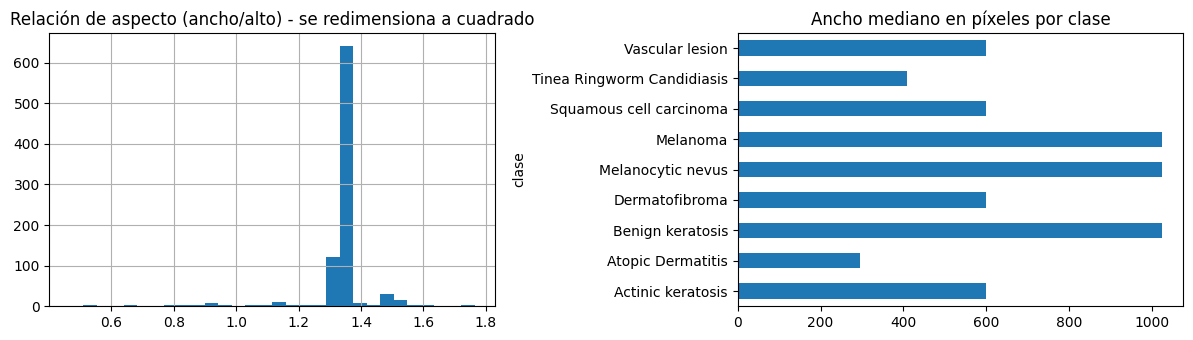

In [ ]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

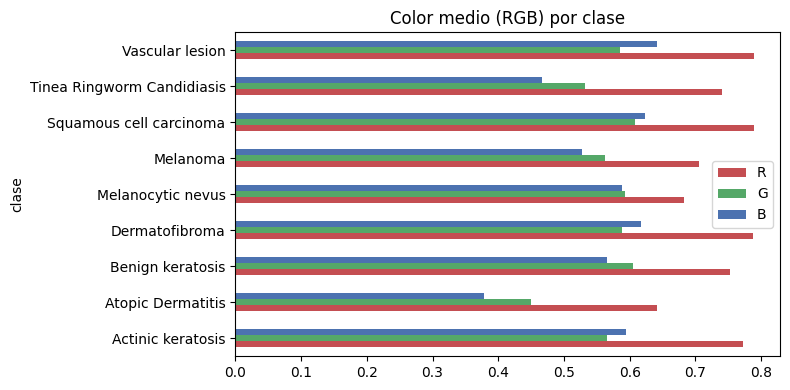

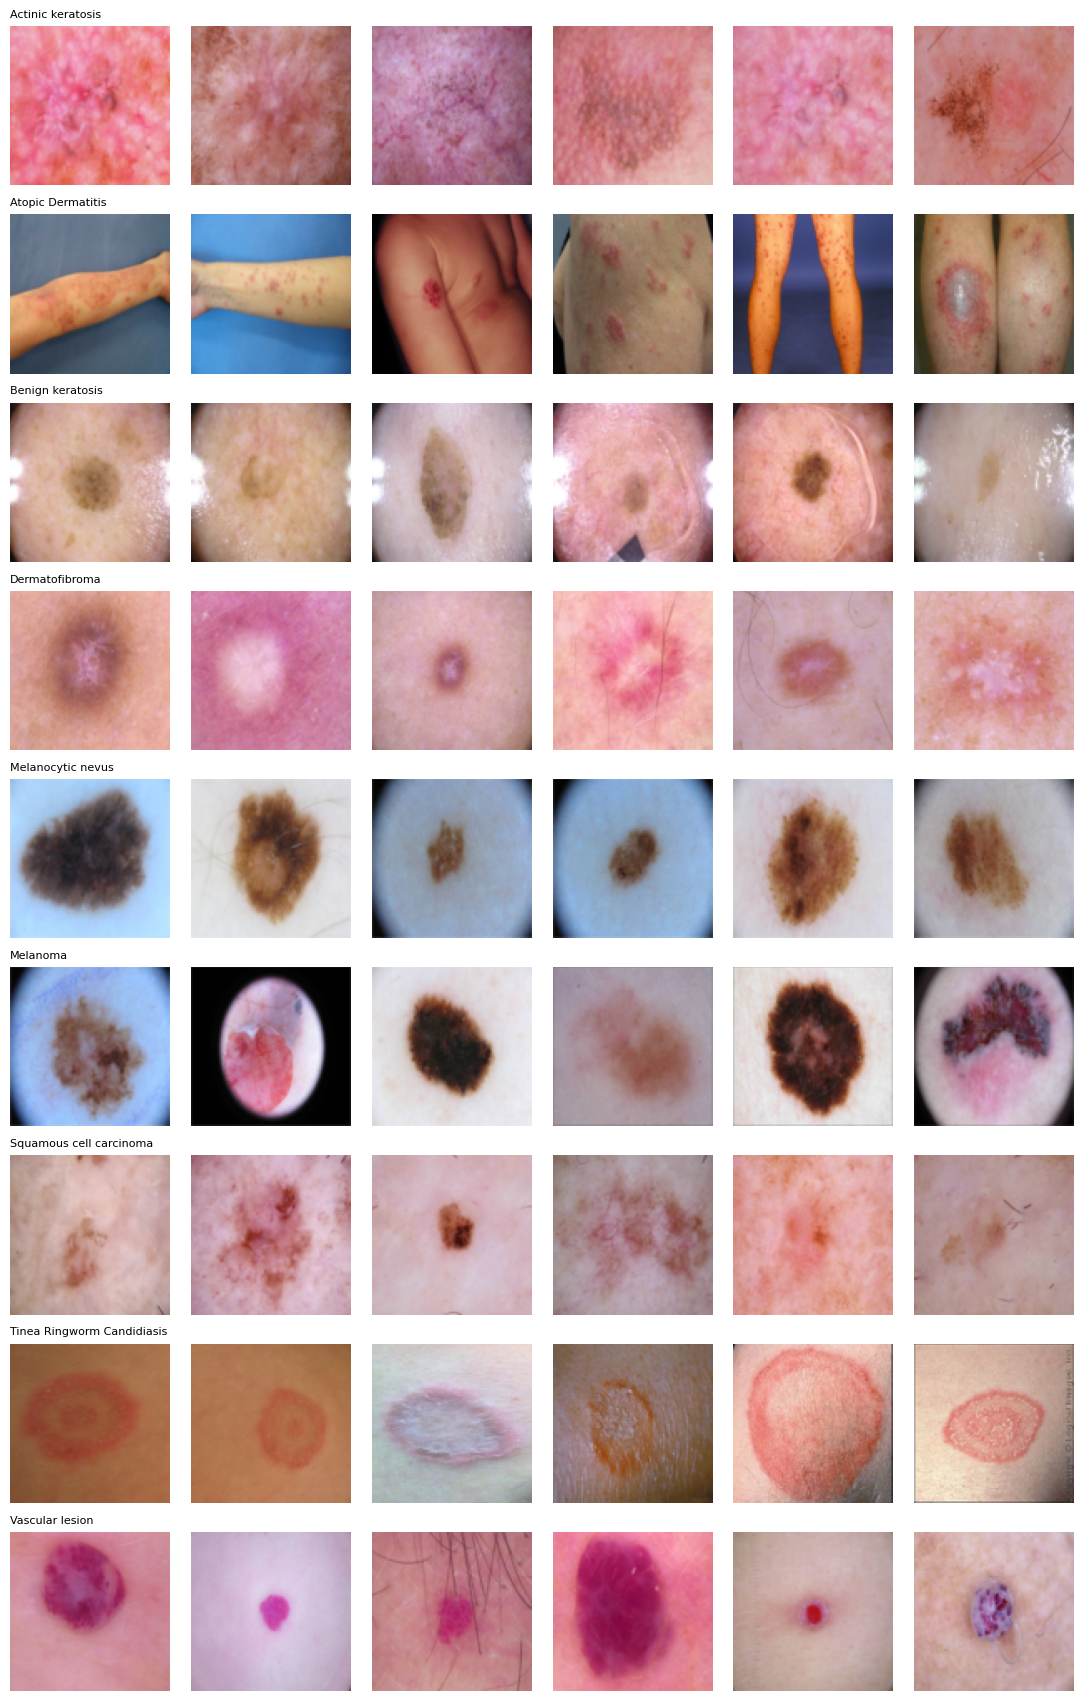

In [ ]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [ ]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?


> **Respuestas:**

1) **Desbalance**: El dataset tiene 878 imágenes en 9 clases y está casi balanceado: 100 imágenes por clase, salvo *Atopic Dermatitis* (con 102 imágenes) y *Tinea Ringworm Candidiasis* (con 76). La partición original reparte 697 imágenes a *train* y 181 a *val*. Al eliminar los 34 duplicados (de 878 en total a 844), *Atopic Dermatitis* queda con 80 imágenes y *Tinea Ringworm Candidiasis* con 64, por lo que el desbalance aumenta un poco y ***Tinea Ringworm Candidiasis* pasa a ser la clase más chica**.

2) **Resolución y color**: La resolución podría servir para identificar las clases, ya que se puede observar como *Atopic Dermatitis* es siempre 294×222 y cuatro clases son siempre 600×450 (*Actinic keratosis*, *Dermatofibroma*, *Squamous cell carcinoma*	y *Vascular lesion*). Por otro lado, las clases *Atopic Dermatitis* y *Tinea Ringworm Candidiasis* son imágenes clínicas con fondos y colores distintos del resto, ya que ambas tienen el color azul más bajo (respecto a las otras clases), siendo la clase *Atopic Dermatitis* la que tiene el nivel de azul más bajo de todas las clases. Respondiendo a la última pregunta de este ítem, al redimensionar a cuadrado la imagen se deforma y se pierde nitidez de forma distinta según la resolución original, el riesgo es que la red aprenda esos atajos (resolución, fondo, viñeta) y no la lesión en sí, lo que inflaría la validación sin generalizar a otras imágenes.

3) **Duplicados**: Hay 34 grupos de imágenes idénticas, de los cuales 33 de ellos están repetidos entre *train* y *val*. Están concentrados en solo dos clases, ***Atopic Dermatitis*** (con 22 grupos) y ***Tinea Ringworm Candidiasis*** (con 12 grupos), y **no hay conflictos de etiqueta**. Son importantes porque las copias de *val* ya fueron vistas en *train*, y entonces la ***val_acc* deja de medir generalización**. Como *ejemplo hipotético*, si el modelo memoriza esas 33 imágenes de las 181 de *val* y acierta el 50% de las otras 148, la *val_acc* sería de aproximadamente 0.59 en vez de 0.50, unos 9 puntos de más (el *val_acc* se obtiene de calcular: (33 + 148×0.5)/181).

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [ ]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

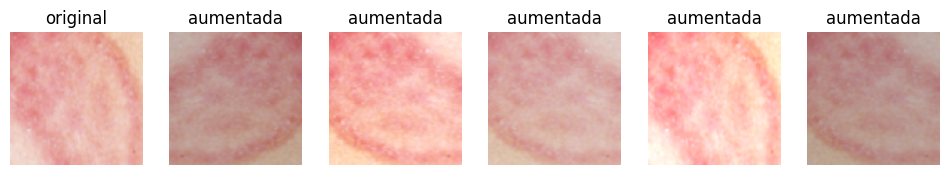

In [ ]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [ ]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [ ]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

> **Respuestas:**

1) **`padding=kernel // 2`**: Con kernel = 3, el padding es 1 y la convolución conserva alto y ancho *(padding “same” según la página 11 del apunte teórico de Redes Neuronales Convolucionales)*. En la tabla que se aprecia arriba de esta sección teórica, la primera fila **Conv2d** entra con una imagen de 64×64 píxeles, y sale (16, 64, 64). Por otra parte, respondiendo a la pregunta de que ocurre si padding=0 *(padding “valid” según la página 11 del apunte teórico de Redes Neuronales Convolucionales)* se perderían 2 píxeles por convolución *(sale de calcular k−1)*. Es decir, saldría una imagen de 62×62, y los bordes se procesarían parcialmente.

2) **`MaxPool2d(2)`**: Lo que hace *MaxPool2d(2)* es dividir el alto y el ancho por 2: en la tabla, 64×64 → 32×32 → 16×16 → 8×8 después de los tres bloques. Se queda con el máximo de cada ventana de 2×2 (es decir, conserva la activación más fuerte) y no tiene parámetros (vale 0 en la tabla). Por eso, después de *n_blocks pooling*, el lado del mapa es size // 2**n_blocks: 64 // 8 = 8, y el Flatten da 64·8·8 = 4096 (fila 12).

3) **Parámetros:** En cuanto a los parámetros que tiene la segunda `Conv2d` 16→32 con kernel 3, se calcula: 3*3*16*32 = 4.608 (obsérvese la fila 4 de la tabla). Para la primera `Linear` de la cabeza, se calcula: 4096*128 + 128 = 524.416 (obsérvese la fila 13 de la tabla). De las dos, domina la `Linear`, con 95,47% del total (524.416 / 549.273), porque conecta cada una de las 4096 entradas con cada neurona sin pesos compartidos, mientras los filtros se reutilizan en todas las posiciones.

4) **`bias=not use_bn`:** El BatchNormalization resta la media de cada canal, así que un sesgo constante en la convolución se cancela. Además la BN tiene su propio β. En la tabla, la primera conv tiene 432 = 27*16 parámetros (sin sesgo) y la BN tiene 32 (γ y β).

5) **`filters * 2 ** b`:** El pooling reduce las posiciones espaciales a la cuarta parte. Duplicar los canales hace que los valores por bloque bajen de forma gradual (de 16.384 a 8.192, y luego a 4.096). Las primeras capas detectan patrones simples, y las siguientes combinan los patrones en otros más complejos, que necesitan más filtros (como LeNet-5, *página 14 del apunte teórico de Redes Neuronales Convolucionales*).

6) **`rf_full`:** El campo receptivo es cuántos píxeles de la imagen original influyen en un único valor de un mapa de esa capa. El paso a paso es: un valor de la *conv1* (k=3) mira un cuadrado de 3×3 → 3. El pool 2×2 mira 2 valores vecinos, y eso suma 1 → 4. Desde acá, dos valores vecinos del mapa están a 2 píxeles en la imagen. La *conv2* mira 3 vecinos separados por 2 píxeles, o sea (3−1)*·2 = 4 más → 8. El pool suma 2 → 10 y los vecinos pasan a estar a 4 píxeles. La *conv3* suma (3−1)*4 = 8 → 18. Entonces, cada unidad de la última *convolución* depende de un parche de 18×18 de la imagen de 64×64 (28% del lado, representando el 8% del área). Es decir, solo ve contexto local, y la combinación global la hace después la capa *Linear*.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 9 | val_acc 0.663 | train_acc 0.781 | 0.18 s/época | total 11s


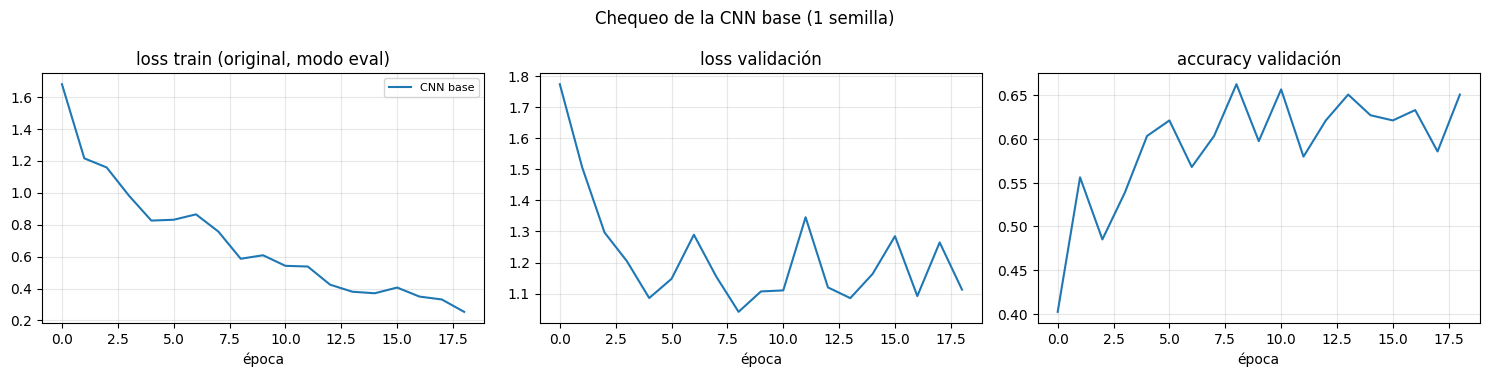

In [ ]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0427,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0587,0.4372,0.0874
2,CNN 32px,156057,0.6469,0.0291,0.8202,0.1732,9.3333,0.0641,0.5812,0.0657
3,CNN 64px,549273,0.6351,0.0366,0.8221,0.1870,12.0000,0.0913,0.5654,0.0697


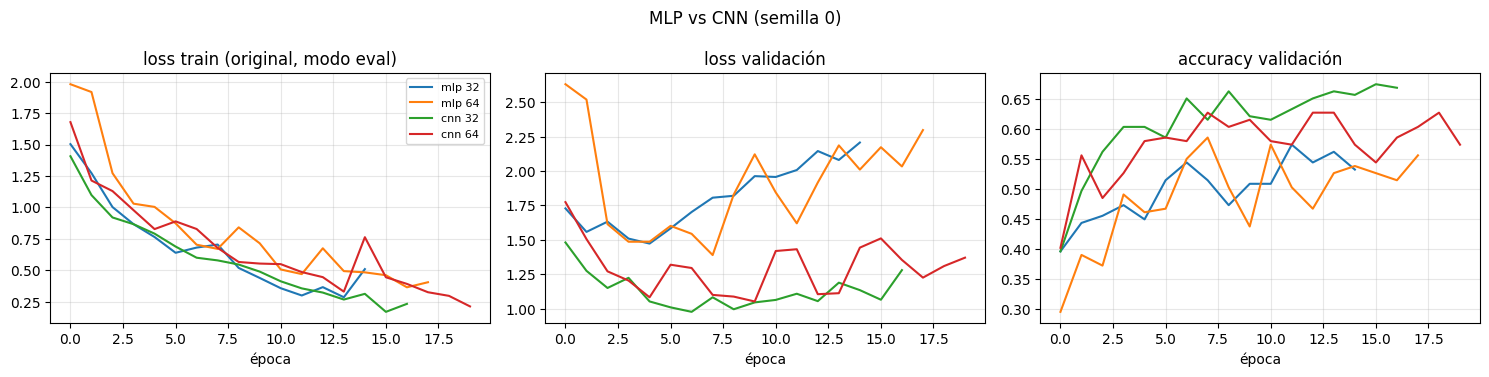

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [ ]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

> **Respuestas:**

1) **Comparación a 32px y 64 px**: A *32 px*, la **MLP** tiene 1.640.201 parámetros y la **CNN** 156.057 (casi 10 veces menos). A *64 px*, 6.358.793 contra 549.273 (aproximadamente 12 veces menos). En *val_acc* la **CNN** gana en las dos resoluciones: 0.647 ± 0.029 contra 0.495 ± 0.039 a *32 px* (+0.15) y 0.635 ± 0.037 contra 0.525 ± 0.043 a *64 px* (+0.11). Ambas diferencias superan el desvío entre semillas y son entre 2 y 3 veces el error estándar de la diferencia (aproximadamente de 0.054, binomial con 169 imágenes), así que son reales, aunque no abrumadoras. La brecha *train-val* es parecida en los cuatro modelos (0.17–0.24), pero la **MLP** sobreajusta antes, ya que su mejor época es la 5.0 *(32 px)* y 6.7 *(64 px)*, y después su *val_loss* sube hasta aproximadamente 2.2–2.3, mientras que la de la *CNN* se mantiene entre 1.0 y 1.5 **(valores leídos de las curvas)**. En cuanto al *tiempo por época*: **MLP** 0.043 s *(32 px)* y 0.059 s *(64 px)*, **CNN** 0.064 s y 0.091 s. Por otra parte, las *épocas de convergencia* son 5.0 y 6.7 **(MLP)** contra 9.3 y 12.0 **(CNN)**. Entre resoluciones del mismo modelo no hay diferencia real *(0.012 en la CNN y 0.030 en la MLP)*. Según una estimación propia, la **CNN** a *64 px* hace aproximadamente 11.7 M de multiplicaciones por imagen contra aproximadamente 6.4 M de la **MLP**, por eso cada época le lleva más tiempo aunque tenga menos parámetros, ya que los pesos compartidos se reutilizan en cada posición.

2) **Parámetros de la MLP**: La **MLP** aplana la imagen, así que cada píxel de cada canal es una entrada, y la primera capa conecta cada entrada con cada neurona. A *32 px* son 3*32*32 = 3.072 entradas, por lo que con 512 neuronas son 3.072*512 + 512 = 1.573.376 parámetros. A *64 px* hay 4 veces más píxeles (12.288 * 512 + 512 = 6.291.968). A *224 px* serían 150.528 entradas y aproximadamente 77 millones de parámetros solo en esa capa. Por lo tanto, crece con el número de píxeles y se vuelve inmanejable y propenso al overfitting *(página 3 del documento teórico de Redes Neuronales Convolucionales)*. En la convolución, un filtro de 3×3×3 tiene 27 pesos que se reutilizan en toda la imagen (pesos compartidos), y cada valor de salida depende solo de un vecindario de 3×3 (conectividad local). Por eso la primera *conv* tiene 16*27 = 432 parámetros a cualquier resolución, y solo crece la *Linear* de la cabeza.

3) **Traslaciones**: En cuanto a la caída por traslación, la misma es de 0.0605 y 0.0874 en la MLP *(32px y 64px respectivamente)*, y de 0.0657 y 0.0697 en la CNN *(32px y 64px respectivamente)*. En puntos absolutos son parecidas, y la diferencia entre modelos (de aproximadamente 0.02) es menor que el ruido ( de aproximadamente 0.04). En proporción, la CNN pierde algo menos (entre un 10 y un 11%, contra un 12 a 17%), lo que sería coherente con la teoría (pesos compartidos, equivarianza), pero el ruido no permite concluir. Además, la traslación es circular (torch.roll) y el pooling da invarianza solo aproximada.

4) **Normalización**: La *media* y el *desvío* por canal fueron calculados solo con train (a 64 px: media [0.743, 0.572, 0.565], desvío [0.162, 0.164, 0.186]), así no se filtra información de *val* y *test*. Al dejar la entrada centrada y con escala parecida, ayuda a que el optimizador sea más estable. *Es importante aclarar que no se probó sin normalizar, así que lo esperado es teoría y no resultado.*

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6233,0.0228,0.7470,0.1238,9.6667,0.0856,1.6944
1,2 bloques,8,1055001,0.6154,0.0242,0.8729,0.2575,16.6667,0.0718,1.9196
2,4 bloques,38,361113,0.6312,0.0543,0.7885,0.1574,13.3333,0.0921,2.1328
3,kernel 5,32,591001,0.6174,0.0393,0.8393,0.2219,18.0000,0.0891,2.5008
4,kernel 7,46,653593,0.6055,0.0028,0.8340,0.2285,22.3333,0.1108,3.5839
5,8 filtros,18,269521,0.6706,0.0405,0.9104,0.2398,14.0000,0.0814,1.9408
6,32 filtros,18,1143337,0.6134,0.0307,0.8149,0.2015,17.0000,0.1135,3.0669
7,32 px,18,156057,0.6430,0.0238,0.8076,0.1646,8.3333,0.0715,1.3068
8,96 px,18,1204633,0.5562,0.0167,0.7596,0.2033,13.3333,0.1264,2.9511


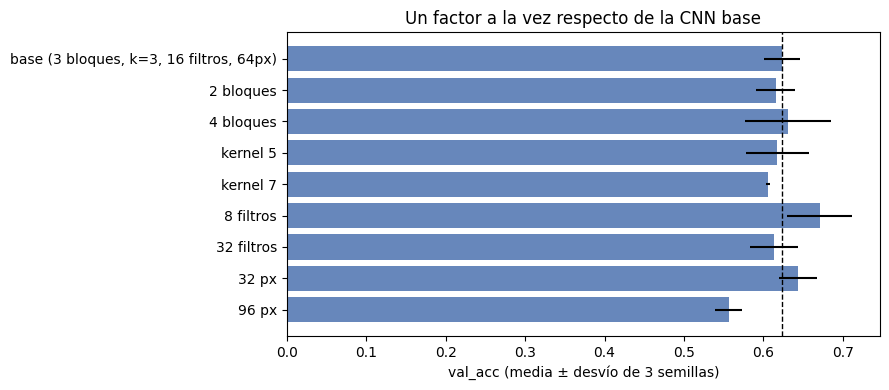

In [ ]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?


> **Respuestas:**

1) **Más allá del ruido entre semillas**: Sólo la variante *96 px* (0.556 contra 0.623 de la base, es decir −0.067) supera claramente el desvío entre semillas (que es de 0.017–0.023). La variante *8 filtros* (+0.047, desvío 0.041) es sugestiva pero no confirmada, ya que la diferencia es del mismo orden que el desvío. *Como referencia, dos corridas de la misma configuración en GPU dieron 0.6233 y 0.6371 (aproximadamente 0.014 de ruido)*. El resto de las variantes está dentro del ruido: la variante *2 bloques* con −0.008, *4 bloques* con +0.008, *kernel 5* con −0.006,  *kernel 7* con −0.018, *32 filtros* con −0.010, y *32 px* con +0.020.

2) **Profundidad y kernel**: El campo receptivo es de 8 px con 2 bloques (12% del lado de 64 px), 18 px con la base (28%), 32 con kernel 5 (50%), 38 con 4 bloques (59%) y 46 con kernel 7 (72%). Para bordes y texturas finas alcanza un campo chico, pero para la asimetría o la forma global de la lesión haría falta uno más parecido al tamaño de la lesión. Se esperaba encontrar una mejora con más campo receptivo, pero no se observó. Como se puede apreciar en la tabla, los valores de *val_acc* de cada variante fue: 4 bloques --> 0.6312, kernel 5 --> 0.6174 y kernel 7 --> 0.6055, contra 0.6233 de la base, todo dentro del ruido. Sin embargo, si se puede apreciar que el costo sube: el kernel 7 usa +19% de parámetros (653.593 contra 549.273 de la base) y +29% de tiempo por época (0.1108 contra 0.0856 s de la base). Los 4 bloques logran lo mismo con 361.113 parámetros (34% menos), porque el mapa final es de 4×4 y la *Linear* se achica. Con 2 bloques hay más parámetros (1.055.001) porque el mapa final es de 16×16.

3) **Resolución**: La *Linear* de la cabeza recibe 64·fs² entradas, con fs = size // 8: 1.024 a 32 px, 4.096 a 64 px y 9.216 a 96 px. Con 128 neuronas son 131.200, 524.416 y 1.179.776 parámetros (los convolucionales casi no cambian, aproximadamente 23.700). Subir la resolución da más detalle disponible, pero cuesta cómputo (0.072, 0.086 y 0.126 s por época) y el campo receptivo, siempre de 18 px, cubre una fracción cada vez menor de la imagen (56%, 28% y 19% del lado). 32 px da lo mismo que la base (0.643 contra 0.623, dentro del ruido) con 3.5 veces menos parámetros, y 96 px es peor (0.556). En cuanto al límite que tiene el experimento, con unas 56 imágenes por clase la red no puede aprovechar el detalle ni los parámetros extra, y como cambian a la vez los parámetros, el campo receptivo relativo y la información, no se puede aislar cuál causa la caída.

4) **Límite**: Con un factor a la vez y 3 semillas, no se puede concluir:
    - Cómo interactúan los factores (por ejemplo, 4 bloques con 32 px).
    - Que una diferencia “dentro del ruido” sea nula, porque solo significa que no se detecta.
    - Nada preciso sobre el desvío ya que, con n = 3, *np.std* (divide por n) lo subestima en aproximadamente 18 %.
    - Nada que no sea con esta única partición, sumado al ruido de GPU.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6371,0.0393,0.7628,0.1258,1.0305,11.3333,0.0810,1.7278
1,flips,1518,0.6055,0.0391,0.8030,0.1975,1.0036,7.0000,0.2401,4.0786
2,flips+rot90,1518,0.6450,0.0466,0.8854,0.2404,1.0081,14.0000,0.2418,5.8035
3,flips+rot90+color,1518,0.6450,0.0211,0.7787,0.1337,1.0307,8.6667,0.2388,4.4424


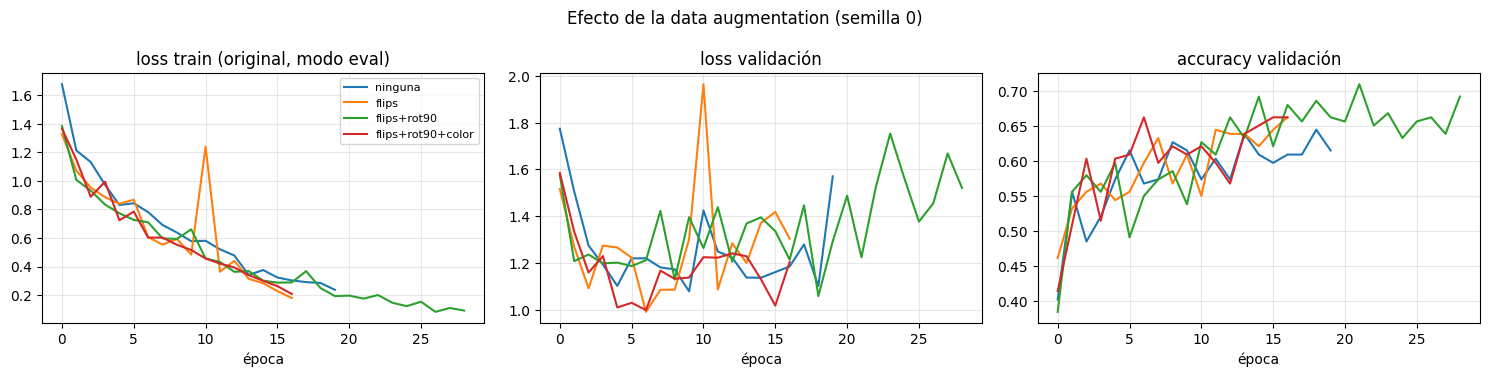

In [ ]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?.

> **Respuestas:**

1) **Overfitting sin augmentation**: La brecha de 0.126 (*train* 0.763, *val* 0.637) en la mejor época (11.3 en promedio). En la corrida de chequeo (con semilla 0), la época de mejor *val_loss* fue la 9 (con *val_acc* 0.663 y *train_acc* 0.781). La *loss* de *train* sigue bajando de 1.7 a aproximadamente 0.25 (hacia la época 18), mientras la *val_loss* tiene su mínimo (de aproximadamente 1.04) y después fluctúa entre 1.1 y 1.35 *(los valores son aproximados ya que son leídos de las curvas)*.

2) **Efecto de cada nivel**: Sin *augmentation* se obtiene una brecha de 0.126, un *val_loss* de 1.031, una *val_acc* de 0.637 ± 0.039, una *mejor época* de 11.3 y 1.7 s totales. Por otra parte, con *flips*: 0.198, 1.004, 0.606 ± 0.039, época 7.0 y 4.1 s, respectivamente. Con *flips+rot90*: 0.240, 1.008, 0.645 ± 0.047, época 14.0 y 5.8 s, respectivamente. Con *flips+rot90+color*: 0.134, 1.031, 0.645 ± 0.021, época 8.7 y 4.4 s, respectivamente. Se puede observar que ninguna diferencia de *val_acc* (de −0.032 a +0.008) supera el ruido, y la *val_loss* es casi igual en todos (1.00–1.03). El color baja la brecha (*train_acc* de 0.779 contra 0.885 con *flips+rot90*) porque actúa como regularizador. Cada época cuesta ×3 porque *train* pasa de 506 a 1.518 imágenes (originales más 2 copias), y el tiempo total sube de 1.7 s a 4–6 s. Las copias se generan una sola vez, así que la diversidad es limitada. Los *augmentation* *Flips+rot90* y *flips+rot90+color* empataron en 0.6450 y el código eligió la de color por el orden de la tabla, no por una diferencia real.

3) **Dermatología**: Los flips y las rotaciones de 90° conservan la forma, el tamaño, el color y la textura de la lesión y solo cambian la orientación, lo cual es razonable para una lesión cutánea, que no tiene una orientación natural. *Sin embargo, es una posibilidad que la relación alto-ancho de una lesión sea significativa dermatológicamente, pero habría que confirmarlo con un experto.* El color es información diagnóstica, así que los cambios fuertes de brillo o contraste pueden destruirla. Los recortes o cambios de escala podrían dejar parte de la lesión fuera de la imagen, y el tamaño absoluto igual no se conserva en este dataset, porque las imágenes tienen distintas resoluciones y se redimensionan a 64×64. Otros *augmentation* a probar serían rotaciones de ángulo arbitrario, recortes suaves, desenfoque o ruido (para ver si baja la dependencia de la nitidez detectada en el EDA), y regenerar las copias en cada época para tener más diversidad.

4) **Después del split y solo en train**: Si se aumentara antes de dividir, versiones transformadas de una misma imagen quedarían en *train* y en *val* o *test*. La red habría visto la imagen, y las métricas se inflarían, igual que con los duplicados que vimos en el EDA. Es importante que tanto *Val* como *test* representen datos nuevos para la CNN.

5) **Comparación con el TP3**: *Dropout* y *L2* (ambos del TP3) restringen los pesos o agregan ruido en las activaciones, y no agregan información nueva, sino que actúan sobre el modelo. La *augmentation*, en cambio, agrega ejemplos sintéticos que codifican conocimiento previo del problema y actúa sobre los datos. Cuesta más cómputo, ya que acá cada época tarda ×3 porque *train* pasa de 506 a 1.518 imágenes, mientras que *L1* y *L2* sumaban aproximadamente el 18% por época en el TP3. En ambos casos el pico de accuracy no mejoró de forma clara.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [ ]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips+rot90+color
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90+color'}
Config final en validación: val_acc 0.641 ± 0.042 | brecha 0.215 | mejor época 10.7 | 5s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6828,0.0255,0.6762,0.0287,4.7918
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,1.0114


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.56      0.75      0.64        20
         Atopic Dermatitis       0.74      0.88      0.80        16
          Benign keratosis       0.66      0.95      0.78        20
            Dermatofibroma       0.55      0.60      0.57        20
         Melanocytic nevus       0.82      0.45      0.58        20
                  Melanoma       0.35      0.30      0.32        20
   Squamous cell carcinoma       0.62      0.40      0.48        20
Tinea Ringworm Candidiasis       0.55      0.46      0.50        13
           Vascular lesion       0.95      0.95      0.95        20

                  accuracy                           0.64       169
                 macro avg       0.64      0.64      0.63       169
              weighted avg       0.64      0.64      0.63       169



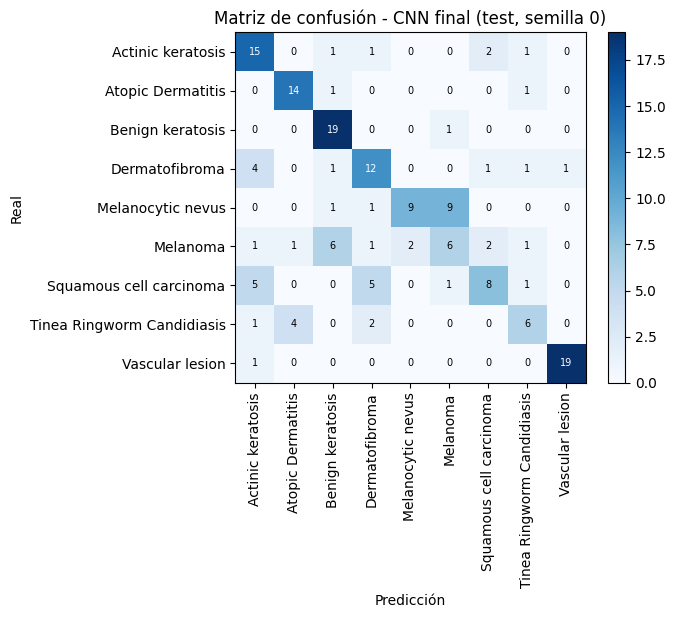

In [ ]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

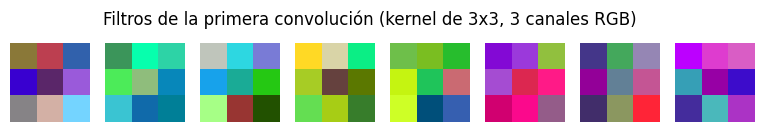

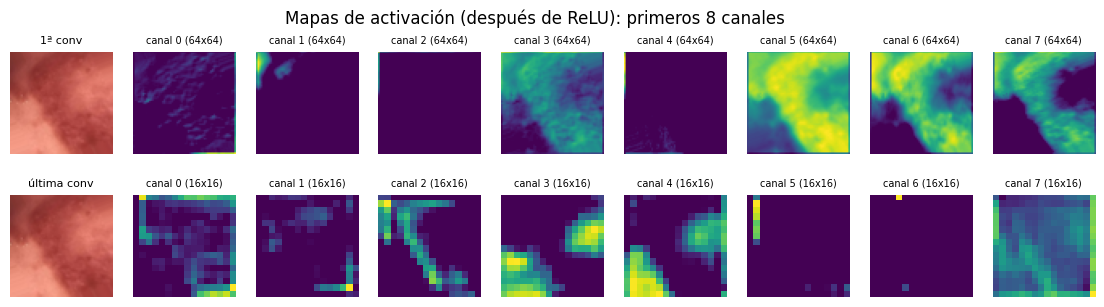

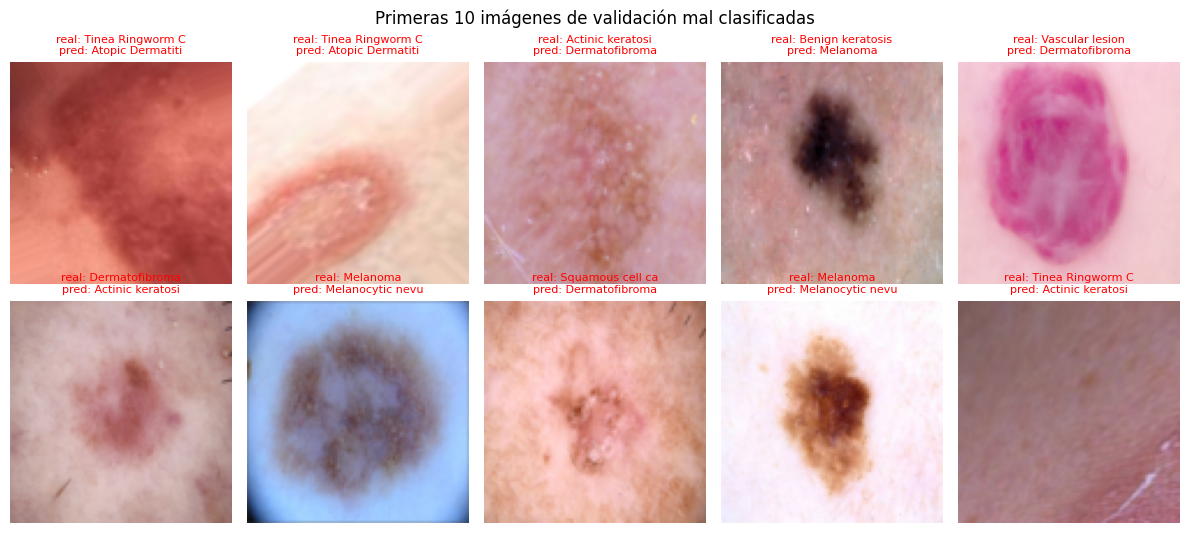

In [ ]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

> **Respuestas:**

1) **Val contra test**: El *test* dio 0.6828 ± 0.0255 (con 5 semillas) y el *error estándar binomial* es ±0.036. En validación, la *config final* dio 0.641 ± 0.042. La diferencia (0.042) es aproximadamente 1.2 errores estándar, así que es coherente. Se esperaría ver que el *test* diera un poco más bajo, porque elegimos entre varias configuraciones sobre validación (es decir, hay un *sesgo optimista*), pero ocurre lo contrario. Esto se lo podemos atribuir al ruido (169 imágenes, con pocas semillas) y no a una mejora real. Además, la combinación *8 filtros + flips+rot90+color* (0.641) no superó a cada factor por separado (0.671 y 0.645, respectivamente), ni tampoco a la base (con 0.623–0.637). Todas esas diferencias están dentro del ruido, así que la **elección final estuvo guiada en buena parte por el ruido**.

2) **CNN vs. MLP en test**: La **CNN** dio 0.683 ± 0.026 y la **MLP** 0.504 ± 0.053 en *accuracy* (*F1 macro* 0.676 contra 0.487). La diferencia (0.18) supera la suma de los desvíos entre semillas y es unas 3.5 veces el error estándar de la diferencia (de aproximadamente 0.051). La **CNN** tiene 24 veces menos parámetros (269.521 contra 6.358.793) a cambio de aproximadamente 4.8 s contra aproximadamente 1 s de entrenamiento en GPU. Por lo tanto, **se justifica el costo en parámetros/tiempo**.

3) **Matriz y reporte (semilla 0, accuracy 0.639, por debajo del promedio de 5 semillas)**: La mejor clase es *Vascular lesion* (con F1 0.95). La peor es *Melanoma* (con F1 0.32, recall 0.30 = 6 de 20). Las confusiones principales son **9 *Melanocytic nevus* predichos como *melanoma***, **6 *melanomas* como *Benign keratosis***, **5 *Squamous cell carcinoma* como *Actinic keratosis* y 5 como *Dermatofibroma***, y **4 *Tinea Ringworm Candidiasis* como *Atopic Dermatitis***. **Sin embargo, no todos los errores son igual de graves: no detectar un melanoma (14 de 20 mal clasificados, 8 como lesiones benignas) es mucho peor que un falso positivo.** Por eso el ***recall* de melanoma** es la **métrica más relevante**, **junto con el F1 macro**, que no esconde las clases débiles como el accuracy. Con 20 imágenes, ese recall tiene un error de aproximadamente ±0.10.

4) **Filtros, mapas y errores**: Los 8 filtros de 3×3 parecen detectores de color e intensidad más que de bordes nítidos, algo esperable con 506 imágenes de entrenamiento. Tras la primera *conv*, algunos canales marcan regiones amplias de la lesión (3, 5, 6, 7), otro resalta textura fina (0) y varios casi no se activan (1, 2, 4), con artefactos de borde por el *padding*. En la última *conv* (16×16), los mapas son más gruesos y abstractos, ya que se observan manchas de la lesión (3, 4), una estructura diagonal (2) y canales casi apagados (5, 6). Las imágenes mal clasificadas son lesiones parecidas entre sí (como *Melanocytic nevus* y *melanoma* oscuros, parches rosados), con poco contraste o sin lesión claramente delimitada. También se repiten errores entre clases del mismo tipo de foto (*Tinea Ringworm Candidiasis* contra *Atopic Dermatitis*, ambas son imágenes clínicas).

5) **Sesgos y limitaciones**: El **EDA** mostró que la resolución casi identifica la clase (*Atopic Dermatitis* siempre 294×222, cuatro clases siempre 600×450) y que hay diferencias de color, fondo y viñeta por clase. Además, *Atopic Dermatitis* y *Tinea Ringworm Candidiasis* son fotos clínicas y el resto dermatoscopías, así que el buen *F1* de *Atopic Dermatitis* (0.80) puede deberse a esos atajos y no al diagnóstico. Los duplicados exactos se eliminaron, pero sin metadatos no se puede descartar que haya imágenes de una misma lesión o paciente repartidas entre *train* y *test*, lo que inflaría los números. El *test* tiene 169 imágenes (±0.036) y solo 13 en la clase más chica (hay una sola partición y 3 semillas). El dataset parece representar sobre todo piel clara, aunque esto no lo corroboramos viendo todas las imágenes. Con más tiempo, se podría hacer validación cruzada o varias particiones, más semillas, partición por paciente, evaluación en otro dataset, Grad-CAM para detectar atajos, y probar sin color o recortando los bordes.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

> Usé Claude (Anthropic) como asistente para entender el código del notebook, revisar la coherencia entre los resultados y los textos. Ejecuté el notebook completo en Google Colab con GPU, sin modificar las constantes. Verifiqué a mano los cálculos de parámetros y de campo receptivo contra la tabla.